In [1]:
import matplotlib.pyplot as plt

from poset import PoSet
from simplicial_complex import SimplicialComplex

# Partially Ordered Set (PoSet)

- Set, $S$; Binary relation, $\preceq$
  - (S, $\preceq$)
  - _Partial_ $\implies$ no all pairs are comparable.
- all elements $x, y, z \in S$:
    - $x \preceq x$ (Reflexive)
    - $x \preceq y$ and $y \preceq x$ $\implies x = y$ (Anti-Symmetry)
    - $x \preceq y$ and $y \preceq z$ $\implies x \preceq z$ (Transitivity)

**Example (below)**

Let R be the relation $\subseteq$, so we then have (S,$\subseteq$)

Note: ((1,), (2,)) is not in R. Neither element is subset of each other so 
it will not be in R. This is what partial ordering allows.

In [2]:
p = PoSet(
    S = {(1,), (2,), (1,2)}, 
    R = {((1,),(1,)), ((2,),(2,)), ((1,2),(1,2)), ((1,),(1,2)), ((2,),(1,2))}
)

print("The relation R on S is:")
print(*sorted(p.R), sep="\n")

The relation R on S is:
((1,), (1,))
((1,), (1, 2))
((1, 2), (1, 2))
((2,), (1, 2))
((2,), (2,))


**Examples of bad PoSets, and error handling**

In [3]:
%%script false --no-raise-error
p_not_reflexive = PoSet(
    S = {1,2,3}, 
    R = {(1,1), (2,2), (1,2), (2,1)},
)

In [4]:
%%script false --no-raise-error
p_not_antisymmetric = PoSet(S = {1,2,3}, 
    R = {(1,1), (2,2), (3,3), (1,2), (2,1)},
)

In [5]:
%%script false --no-raise-error
p_not_transative = PoSet(
    S = {1,2,3}, 
    R = {(1,1), (2,2), (3,3), (1,2), (2,3)},
)

# Simplicial Complex (Abstract)

Finite collection of sets $K$ such that for all 
$\sigma \in K$ and all $\tau \subseteq \sigma$, $\tau \in K$. 
Each set in $K$ is called a simplex.

### How we can talk about Simplicial Complexs:

#### Tools
- n-simplex
- Faces
- Maximal
- Hasse Diagrams

#### Properties
- Dimension
- Connected
- Boundary
- Euler Characteristic
- Surface
- Orientable


### **n-Simplex, Faces, and Maximal**

_n-Simplex_:

- 0-Simplex - Point
- 1-Simplex - Line Segment/Edge
- 2-Simplex - Triangle
- 3-Simplex - Tetrahedron

_Faces_

$\tau$ is called a face $\sigma \in K$ if $\tau \subseteq \sigma$.

_Maximal_

We call a simplex $\sigma \in K$ maximal if it is not a face of another
simplex in $K$.

Maximal simplex: [frozenset({0}), frozenset({1, 2}), frozenset({3, 4, 5}), frozenset({8, 9, 6, 7})]
2-Simplices: {frozenset({9, 6, 7}), frozenset({8, 6, 7}), frozenset({3, 4, 5}), frozenset({8, 9, 6}), frozenset({8, 9, 7})}


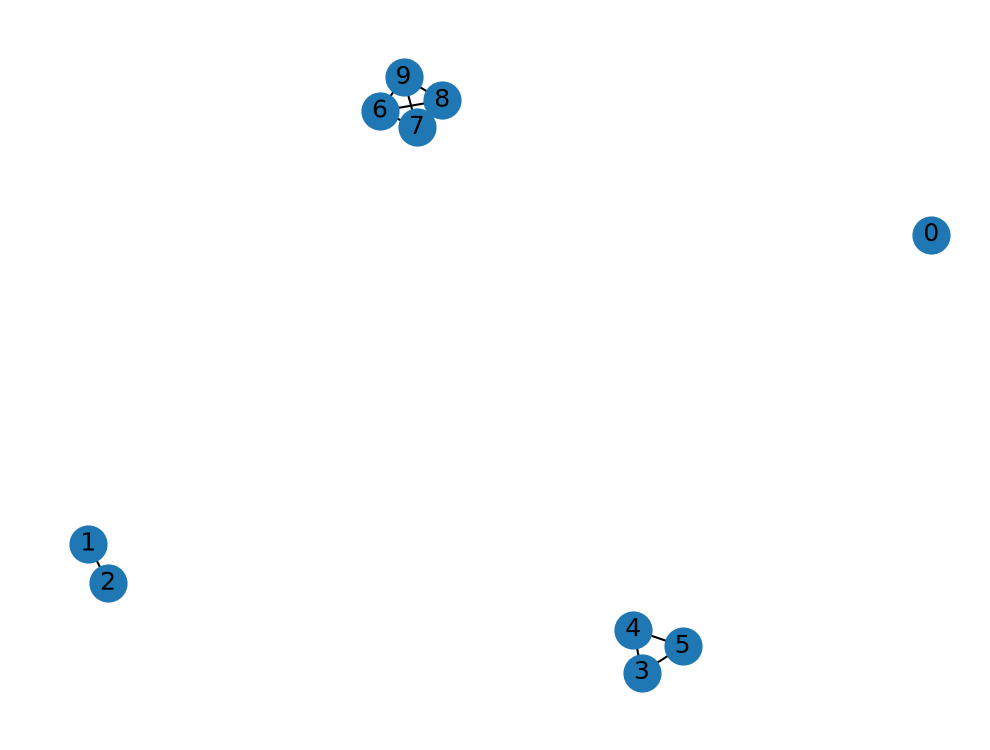

In [6]:
ex_simplicies = SimplicialComplex([(0,), (1,2), (3,4,5), (6,7,8,9)])
print(f"Maximal simplex: {ex_simplicies.maximal()}")
print(f"2-Simplices: {ex_simplicies.n_simplices(2)}")
ex_simplicies.s_complex_graph()

### Hasse Diagrams
Diagrams that show the relationship between our elements of S under our relation R.

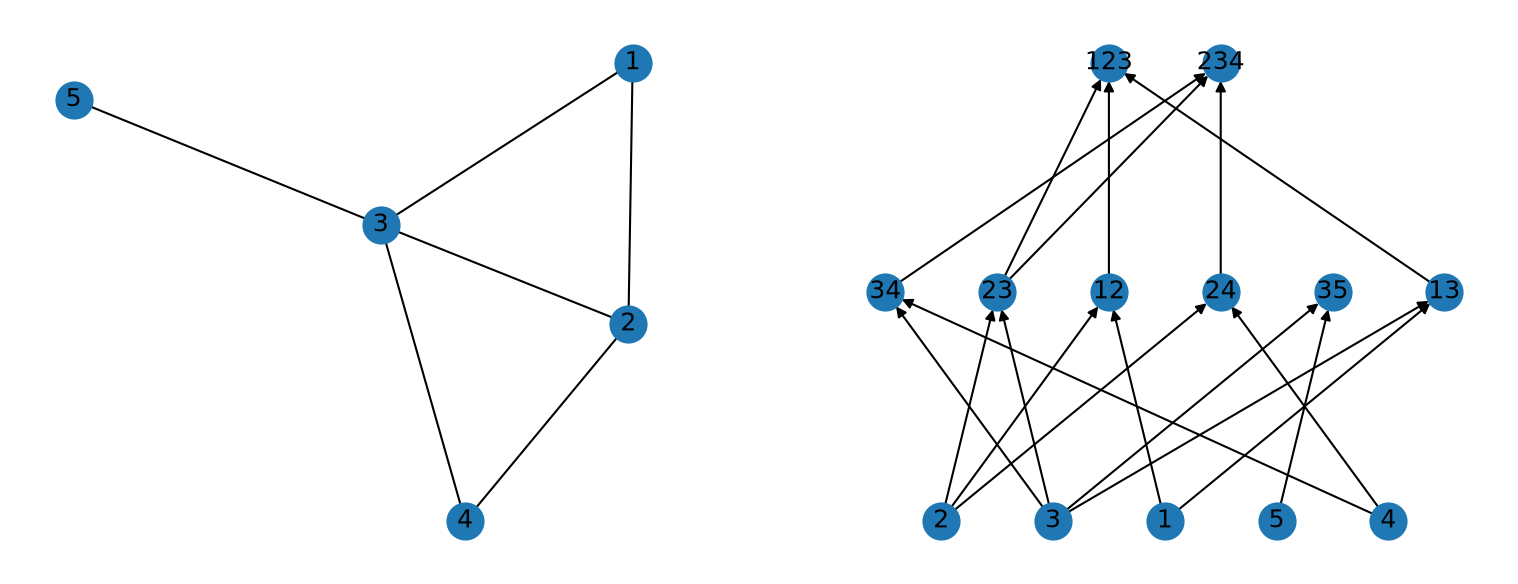

In [7]:
# Two Triangles and a Tail
two_triangles = SimplicialComplex([(1,2,3),(2,3,4),(3,5)])

plt.figure(figsize=(12.8, 4.8))

plt.subplot(1,2,1)
two_triangles.s_complex_graph()

plt.subplot(1,2,2)
two_triangles.draw_hasse()

plt.show()

## **Dimension, Connected, Euler Characteristic**

### Dimension
$\dim(\sigma) = \lvert\sigma\rvert - 1$

$\dim(K) = \max\{\dim(\sigma) : \sigma \in K\}$

### Connected
$K$ is connected if any two 0-simplices can be joined by a path of 1-simplices in $K$.

### Euler Characteristic
$\chi(K) = \sum_{i=0}^{\dim(K)} (-1)^{i} s_{i}$, where $s_{i}$ is the number of $i$-simplices in $K$.

S = {{1}, {2}, {3}, {4}, {5}, {1, 2}, {1, 3}, {2, 3}, {2, 4}, {3, 4}, {3, 5}, {1, 2, 3}, {2, 3, 4}}

Dim: 2
Connected: True
Number of 0-simplices: 5
Number of 1-simplices: 6
Number of 2-simplices: 2
Euler Characteristic: 1


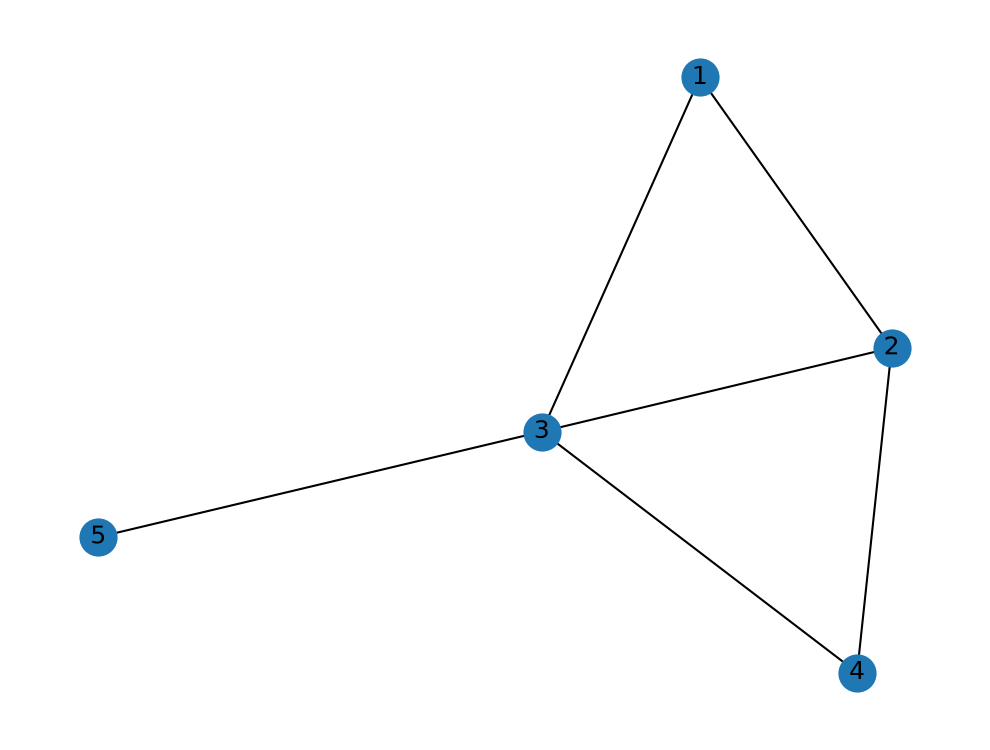

In [9]:
# Simple Example
print(f"{two_triangles}\n")

print(f"Dim: {two_triangles.dim_k()}")
print(f"Connected: {two_triangles.is_connected()}")

for n in range(two_triangles.dim_k()+1):
    print(f"Number of {n}-simplices: {len(two_triangles.n_simplices(n))}")

print(f"Euler Characteristic: {two_triangles.euler_characteristic()}")
two_triangles.s_complex_graph()

## Surface (only triangulations)

1. For every $v \in K$, $\exists$ $\sigma$ that is maximal and $\lvert\sigma\rvert$ = 3.
2. Every 1-simlex is contained in exactly two 2-simplices.


## Boundary

Boundary of two_triangles: ['{5}', '{1, 2}', '{1, 3}', '{3, 4}', '{2, 4}']


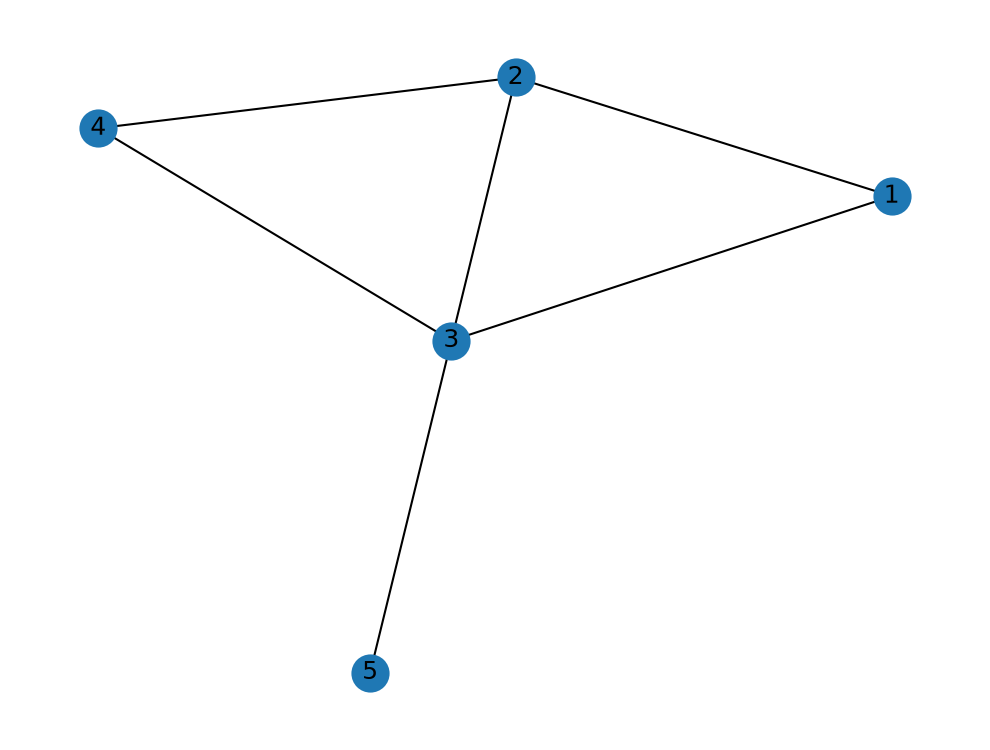

In [7]:
print(f"Boundary of two_triangles: {two_triangles.boundary_k()}")
two_triangles.s_complex_graph()


Elements in complex: 13
Relation set: 37
S = {{1}, {2}, {3}, {4}, {5}, {1, 2}, {1, 3}, {2, 3}, {2, 4}, {3, 4}, {3, 5}, {1, 2, 3}, {2, 3, 4}}

Dim: 2


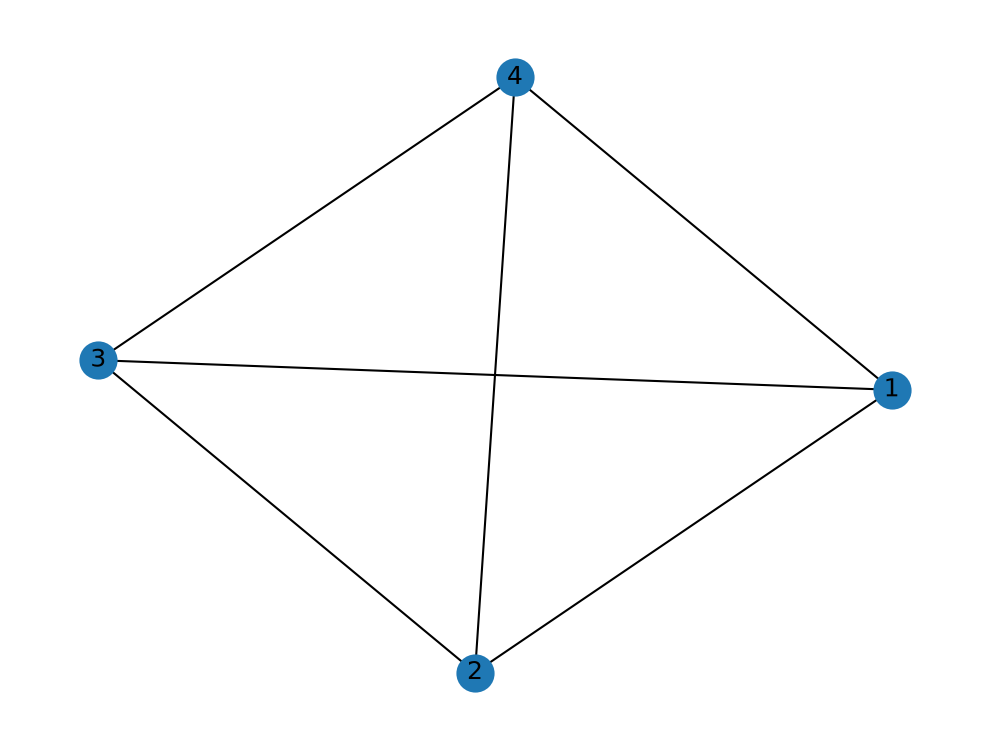

In [8]:
# Tetrahedron/Sphere
sphere = SimplicialComplex([(1,2,3),(1,2,4),(1,3,4), (2,3,4)])
print(f"Elements in complex: {len(two_triangles.S)}")
print(f"Relation set: {len(two_triangles.R)}")
print(two_triangles)

print("")

print(f"Dim: {two_triangles.dim()}")
sphere.s_complex_graph()

## Orientable


Is our complex orientable: False


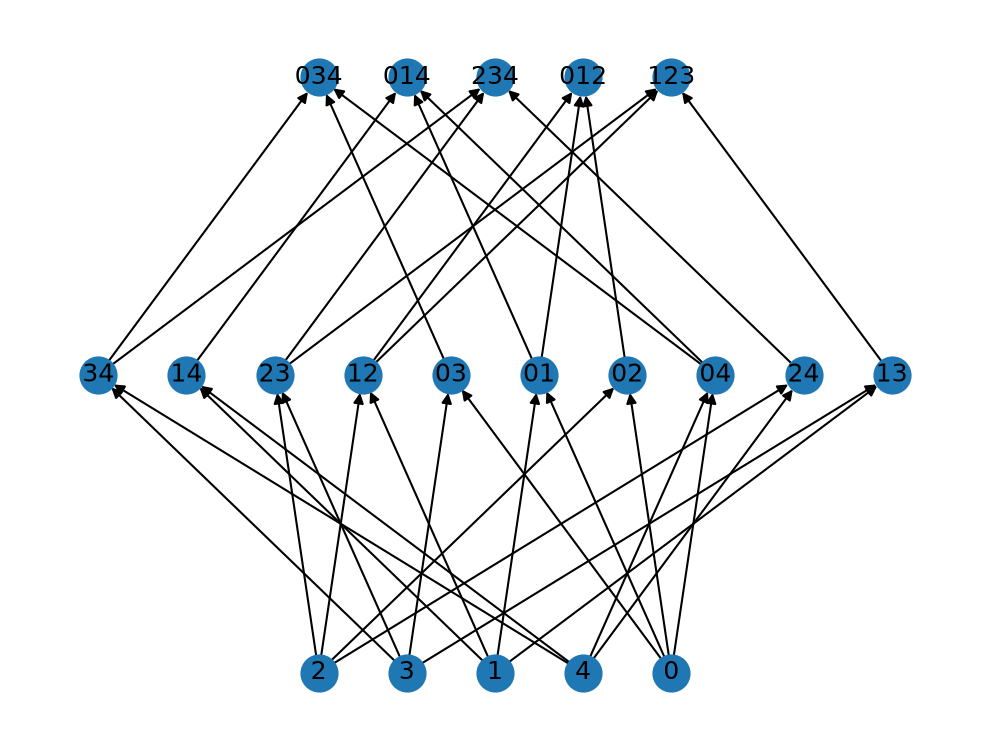

In [11]:
mobius = SimplicialComplex([
    (0, 1, 2),
    (1, 2, 3),
    (2, 3, 4),
    (3, 4, 0),
    (4, 0, 1),
])


#mobius.complex_graph()
mobius.draw_hasse()
print(f"Is our complex orientable: {mobius.is_orientable()}")